# 4. Ingeniería de características y evaluación predictiva

La [metodología](../docs/feature_engineering.md) conecta el EDA con las hipótesis; el [diccionario](../docs/diccionario_features.md) define las entradas y fórmulas. Se predice la carga de primera falla, en N, con geometría previa al ensayo. La evaluación es exploratoria porque las hipótesis se formularon con el EDA del mismo conjunto.

## 4.1 Fuente, configuración e hipótesis

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/experimentos_fe.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.experimentos_fe import run, load_dataset
from src.feature_engineering import make_pipeline, GEOMETRY
from src.informe_fe import decision_matrix
config = json.loads((ROOT/'config/feature_engineering.json').read_text(encoding='utf-8'))
frame = load_dataset(ROOT,config)
display(pd.DataFrame(config['experiments']).T)
display(Markdown('**Objetivo:** `First_Failure_Load_N` [N]. **Modelo fijo:** Ridge, alpha=1. **División:** grupos nominales completos; comprobación secundaria por familia.'))

,reference,intervention
A,None,Geometría original admisible; referencia predi...
B,A,Añadir dos segundos momentos de área de la sec...
C,B,Añadir ln(volumen_pivotes / volumen_fibras)
D,C,"Retirar longitud total de fibras, número de pi..."


**Objetivo:** `First_Failure_Load_N` [N]. **Modelo fijo:** Ridge, alpha=1. **División:** grupos nominales completos; comprobación secundaria por familia.

## 4.2 Decisiones sustentadas en el EDA

In [2]:
display(decision_matrix())

,Hallazgo EDA,Evidencia,Problema u oportunidad,Feature propuesta,Justificación física,Transformación,Riesgo,Experimento
0,Separación entre familias: 96.55 % de variació...,reports/eda/tables/05_descomposicion.csv,Arquitectura dominante; generalización incierta,Conservar n_cells_Y y probar familia excluida,Conteo de celdas previo al ensayo,Conteo numérico; no target encoding,Una familia nueva puede exigir extrapolación,A–D; protocolo secundario
1,Momentos de sección: asociación condicionada p...,reports/eda_transformaciones/tables/T08_asocia...,Hipótesis mecánica aún no validada predictivam...,I_fibra_bh3_mm4; I_fibra_hb3_mm4,Segundos momentos de área de sección rectangul...,b*h^3/12; h*b^3/12,"No son EI, rigidez medida ni criterio de fract...",B − A
2,log(Vp/Vf): rho global 0.8280 y condicionado −...,reports/eda_transformaciones/tables/T08_asocia...,Asociación dependiente de familia; evaluar otr...,log_volumen_pivotes_sobre_fibras,Balance de volúmenes declarados de componentes,"ln(Vp/Vf), adimensional",Asociación explorada con todo el target; posib...,C − B
3,Vf + Vp = 6524.01 mm³; radio constante,reports/eda/tables/12_identidades.csv; reports...,Redundancia algebraica y varianza nula,Retirar Vf del bloque original; filtro de vari...,Los volúmenes complementarios no son efectos i...,Retirada fija de Vf en D; VarianceThreshold en...,Ridge cambia su penalización al cambiar repres...,D − C; A–D
4,Longitud y número de pivotes quedan determinad...,reports/eda/tables/12_mapa_topologia.csv,Descriptores repetidos de arquitectura,Retirar Fiber_total_length y Pivot_total_number,Se conserva el conteo Y,"Reducción física fija, sin elegir por target",Determinismo en este diseño no implica relació...,D − C
5,Rango centrado 7 entre 9 entradas variables; V...,reports/eda_transformaciones/tables/T03_repres...,Colinealidad impide atribuir efectos individuales,Ridge y ablación de bloque,No interpretar coeficientes como mecanismos ai...,Regularización fija alpha=1; diagnóstico de ra...,Retirar columnas modifica regularización efectiva,A–D
6,Log de volumen CAD no reduce asimetría; log de...,reports/eda_transformaciones/tables/T04_logari...,No hay soporte para logaritmos masivos,Una razón logarítmica dirigida,Argumento positivo y adimensional,No transformar target ni todos los volúmenes,Log no añade una medición nueva,C − B
7,Geometría completa; objetivo ausente conservad...,reports/eda_calidad/tables/14_decisiones.csv,No inventar etiquetas ni señales de ausencia,Imputación de entradas dentro del pipeline,Mediana solo de train como contingencia; no re...,SimpleImputer; sin indicadores de ausencia no ...,Futuros nulos deben revisarse; columna sin sop...,A–D
8,Sin alertas IQR/MAD en geometría y target; Coo...,reports/eda/tables/07_atipicos_resumen.csv; re...,Influencia sin justificación de eliminación,Conservar casos y estudiar contribución a erro...,Extremo geométrico puede ser un diseño real,StandardScaler; sin winsorización; RobustScale...,Excluir scores no elimina influencia en modelo...,A–D; sensibilidad descriptiva
9,Factores nominales repetidos; no constan lotes...,reports/eda_calidad/tables/09_configuraciones_...,Dependencia potencial,"Grupo n_cells_Y, Fiber_height, Pivot_height",Mismo conjunto nominal no implica espécimen id...,LeaveOneGroupOut sin dividir el grupo,No controla dependencia de lotes desconocidos,A–D; validación principal


## 4.3 Pipeline y ejecución controlada

Cada fold se divide antes de ajustar mediana, varianza y escalamiento. Las fórmulas geométricas no utilizan el target. A/B/C/D comparten exactamente las particiones; el control Dummy usa la media de entrenamiento.

In [3]:
display(make_pipeline('B'))
summary = run(ROOT)
OUT = ROOT/'reports/feature_engineering'
def table(name):
    return pd.read_csv(OUT/'tables'/f'{name}.csv')
display(summary.loc[summary.protocolo=='configuracion'])

,steps,"[('contract', ...), ('imputer', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,True
,variant,'B'


,protocolo,experimento,feature_set,modelo,MAE_N,RMSE_N,MedAE_N,R2_OOF,MAE_fold_media_N,MAE_fold_sd_N,tiempo_s,prediccion_min_N,predicciones_negativas,n_features_min,n_features_max,n_casos_evaluados,n_folds,delta_MAE_vs_A_N,cambio_MAE_vs_A_pct,delta_RMSE_vs_A_N
0,configuracion,Dummy,Media del entrenamiento,Media de entrenamiento,56.309035,61.716449,61.358400,-0.103595,54.361610,25.697448,0.232606,119.880833,0,9,9,26,24,43.062481,325.084405,45.370723
1,configuracion,A,A · Geometría original,"Ridge(alpha=1, solver=svd)",13.246554,16.345726,11.940893,0.922587,13.640059,9.676509,0.245800,56.060520,0,9,9,26,24,0.000000,0.000000,0.000000
2,configuracion,B,B · A + momentos de sección,"Ridge(alpha=1, solver=svd)",12.834625,16.202866,11.780062,0.923934,13.284741,10.166502,0.503061,55.661117,0,11,11,26,24,-0.411929,-3.109705,-0.142860
3,configuracion,C,C · B + log(Vp/Vf),"Ridge(alpha=1, solver=svd)",12.913867,16.327115,11.864332,0.922763,13.364133,10.266722,0.580922,55.569620,0,12,12,26,24,-0.332687,-2.511496,-0.018611
4,configuracion,D,D · C − descriptores redundantes,"Ridge(alpha=1, solver=svd)",17.034964,21.136079,14.910906,0.870563,17.335498,12.703259,0.635012,55.205151,0,9,9,26,24,3.788411,28.599216,4.790353


## 4.4 Comprobación de generalización entre familias

Excluir una familia completa exige predecir una arquitectura ausente del entrenamiento; no equivale a excluir una configuración dentro del dominio conocido.

In [4]:
display(summary.loc[summary.protocolo=='familia'])
display(table('errores_familia'))

,protocolo,experimento,feature_set,modelo,MAE_N,RMSE_N,MedAE_N,R2_OOF,MAE_fold_media_N,MAE_fold_sd_N,tiempo_s,prediccion_min_N,predicciones_negativas,n_features_min,n_features_max,n_casos_evaluados,n_folds,delta_MAE_vs_A_N,cambio_MAE_vs_A_pct,delta_RMSE_vs_A_N
5,familia,Dummy,Media del entrenamiento,Media de entrenamiento,80.592617,87.521435,84.391667,-1.219406,80.664295,38.870188,0.029685,85.075294,0,9,9,26,3,22.955220,39.826955,27.093299
6,familia,A,A · Geometría original,"Ridge(alpha=1, solver=svd)",57.637397,60.428137,64.519642,-0.058002,57.554693,17.144636,0.036882,6.821429,0,9,9,26,3,0.000000,0.000000,0.000000
7,familia,B,B · A + momentos de sección,"Ridge(alpha=1, solver=svd)",57.653767,60.474030,61.760908,-0.059609,57.465170,17.217171,0.062690,9.991465,0,11,11,26,3,0.016371,0.028403,0.045894
8,familia,C,C · B + log(Vp/Vf),"Ridge(alpha=1, solver=svd)",57.619003,60.527658,61.635140,-0.061489,57.409261,17.529931,0.064637,10.071668,0,12,12,26,3,-0.018394,-0.031913,0.099522
9,familia,D,D · C − descriptores redundantes,"Ridge(alpha=1, solver=svd)",68.834066,71.292274,72.558920,-0.472627,68.856146,16.238457,0.061873,-6.797795,4,9,9,26,3,11.196669,19.426049,10.864137


,protocolo,experimento,familia,n_casos,MAE_N,sesgo_N,error_maximo_N
0,configuracion,A,4,8,15.244343,4.967001,28.147260
1,configuracion,A,5,9,12.505780,-10.970887,32.836227
2,configuracion,A,6,9,12.211515,7.698798,29.921142
3,configuracion,B,4,8,15.635940,4.067437,34.206246
4,configuracion,B,5,9,11.852718,-9.831585,31.403575
5,configuracion,B,6,9,11.326475,6.908741,29.639765
6,configuracion,C,4,8,15.821378,4.020333,35.224750
7,configuracion,C,5,9,11.854207,-9.829795,31.407000
8,configuracion,C,6,9,11.389073,6.840556,29.747582
9,configuracion,D,4,8,15.747276,4.958027,34.191171


## 4.5 Resultados gráficos

Fuente: tabla curada y predicciones fuera de muestra. La dispersión entre grupos no se presenta como intervalo de confianza.

### Figura 1. Error predictivo por representación

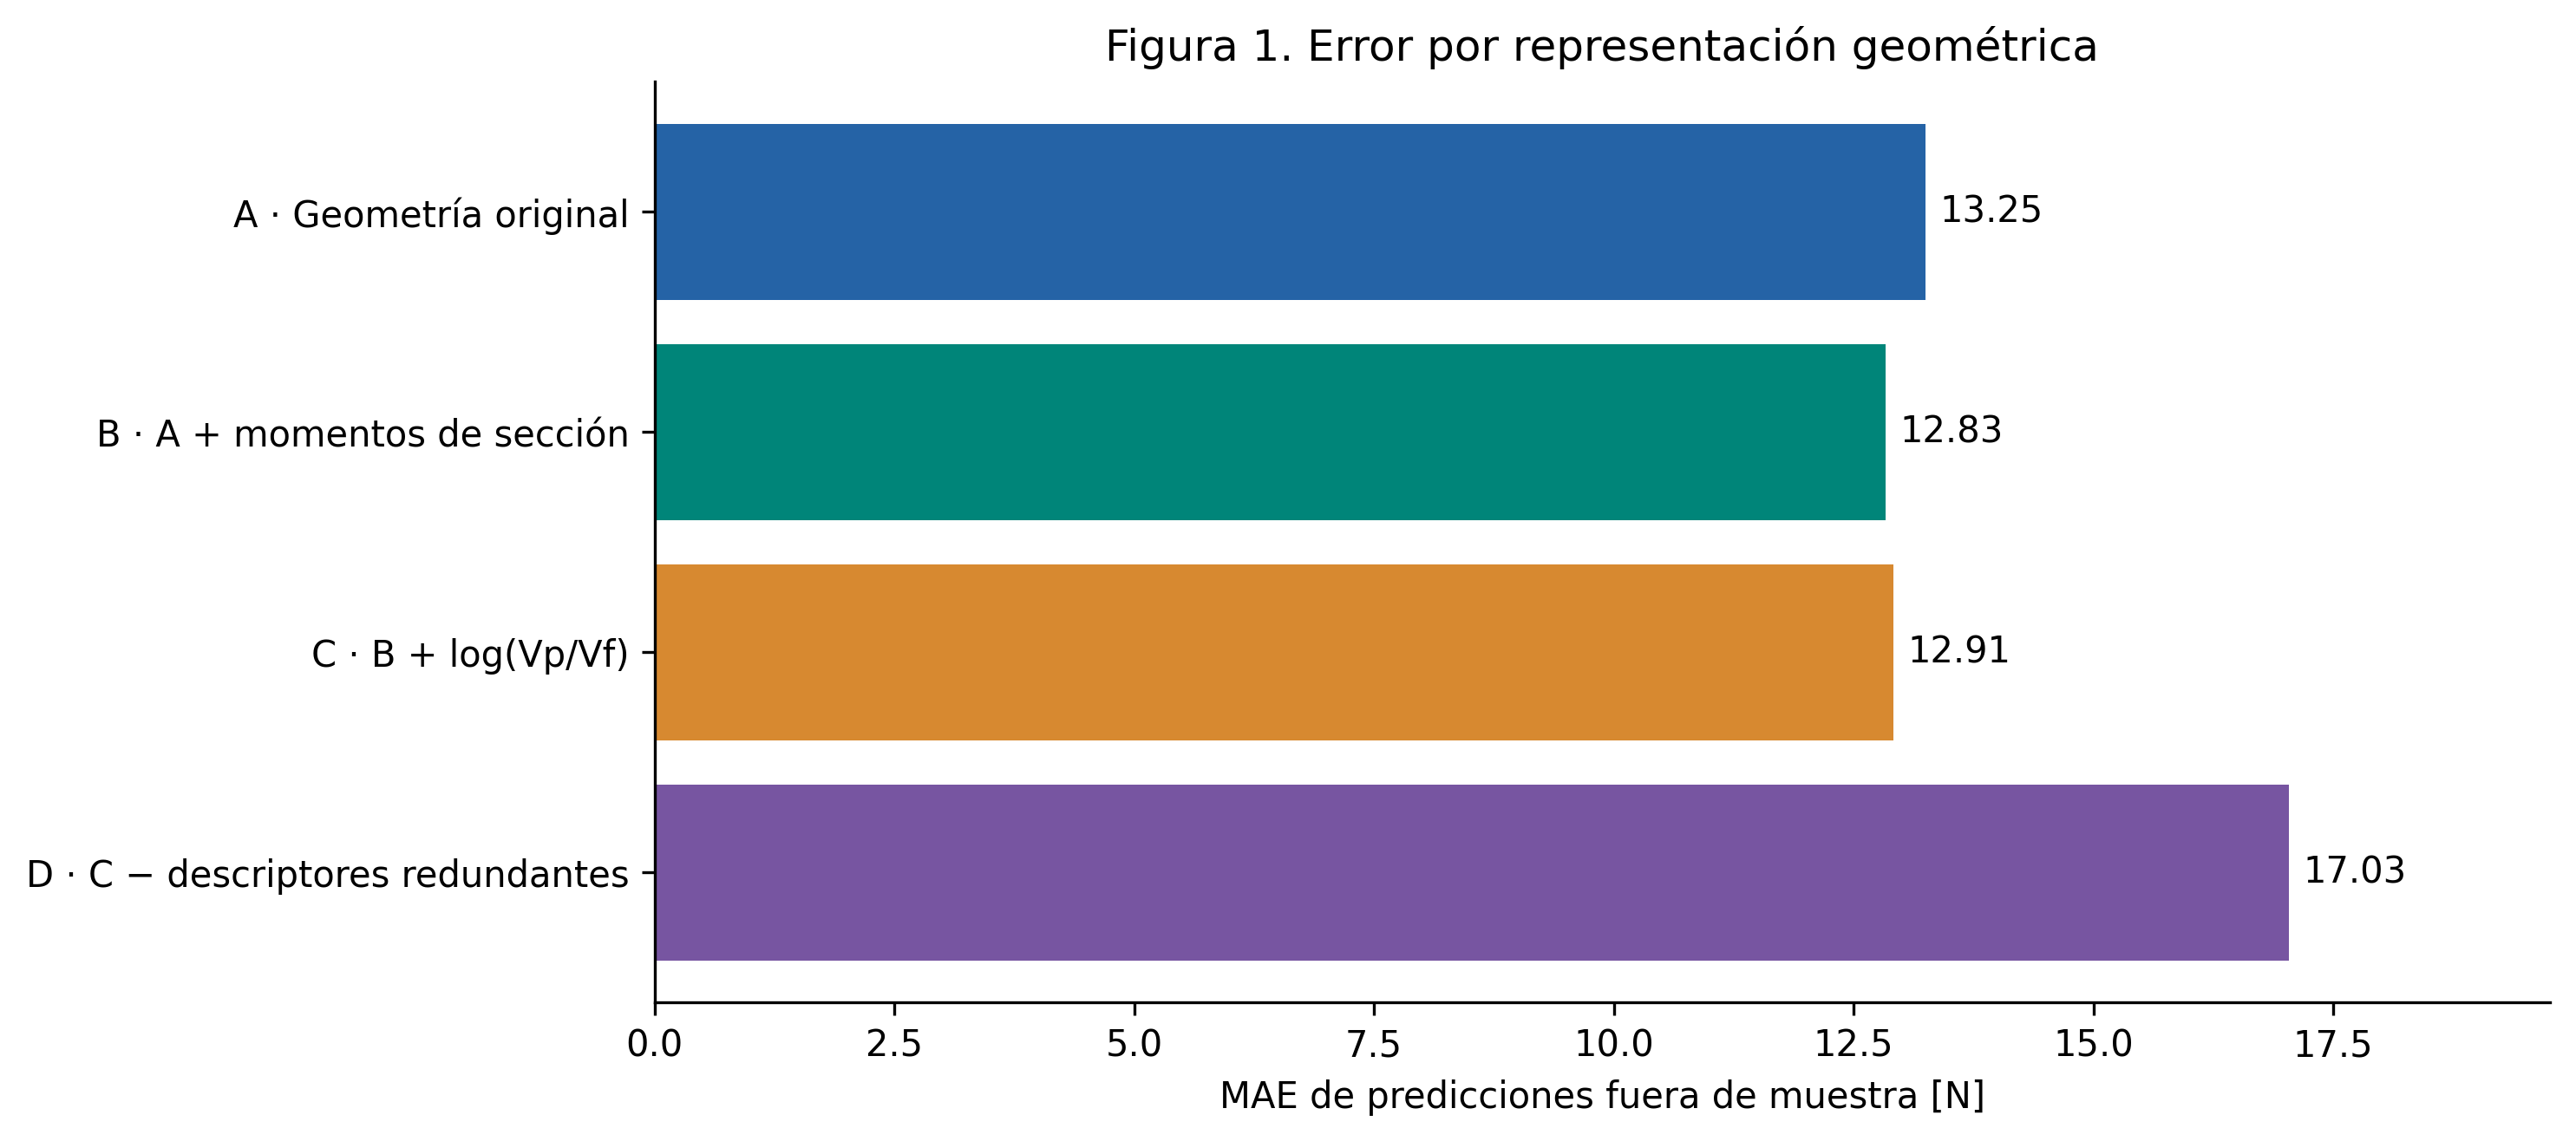

El menor MAE del protocolo principal corresponde a **B**, con **12.8346 N**, frente a **13.2466 N** de A; reducción descriptiva de **3.11 %**. Al excluir familias completas, el MAE de B es **57.6538 N**. El ganador entre variantes examinadas no constituye una estimación independiente del rendimiento de un modelo seleccionado. Las barras muestran MAE agrupado por caso; la dispersión entre grupos se presenta en la figura 5 y en metricas_folds.csv, no como intervalos de confianza.

**Fuente y unidades:** Tabla curada publicada; predicciones fuera de muestra bajo los protocolos indicados. Fuerzas y errores en N.

In [5]:
captions = json.loads((OUT/'leyendas.json').read_text(encoding='utf-8'))
c = captions[0]
display(Markdown('### '+c['title']))
display(Image(filename=str(OUT/'figures'/(c['file']+'.png')), width=1000))
display(Markdown(c['interpretation']+'\n\n**Fuente y unidades:** '+c['source']))

### Figura 2. Predicción fuera de muestra frente a observación

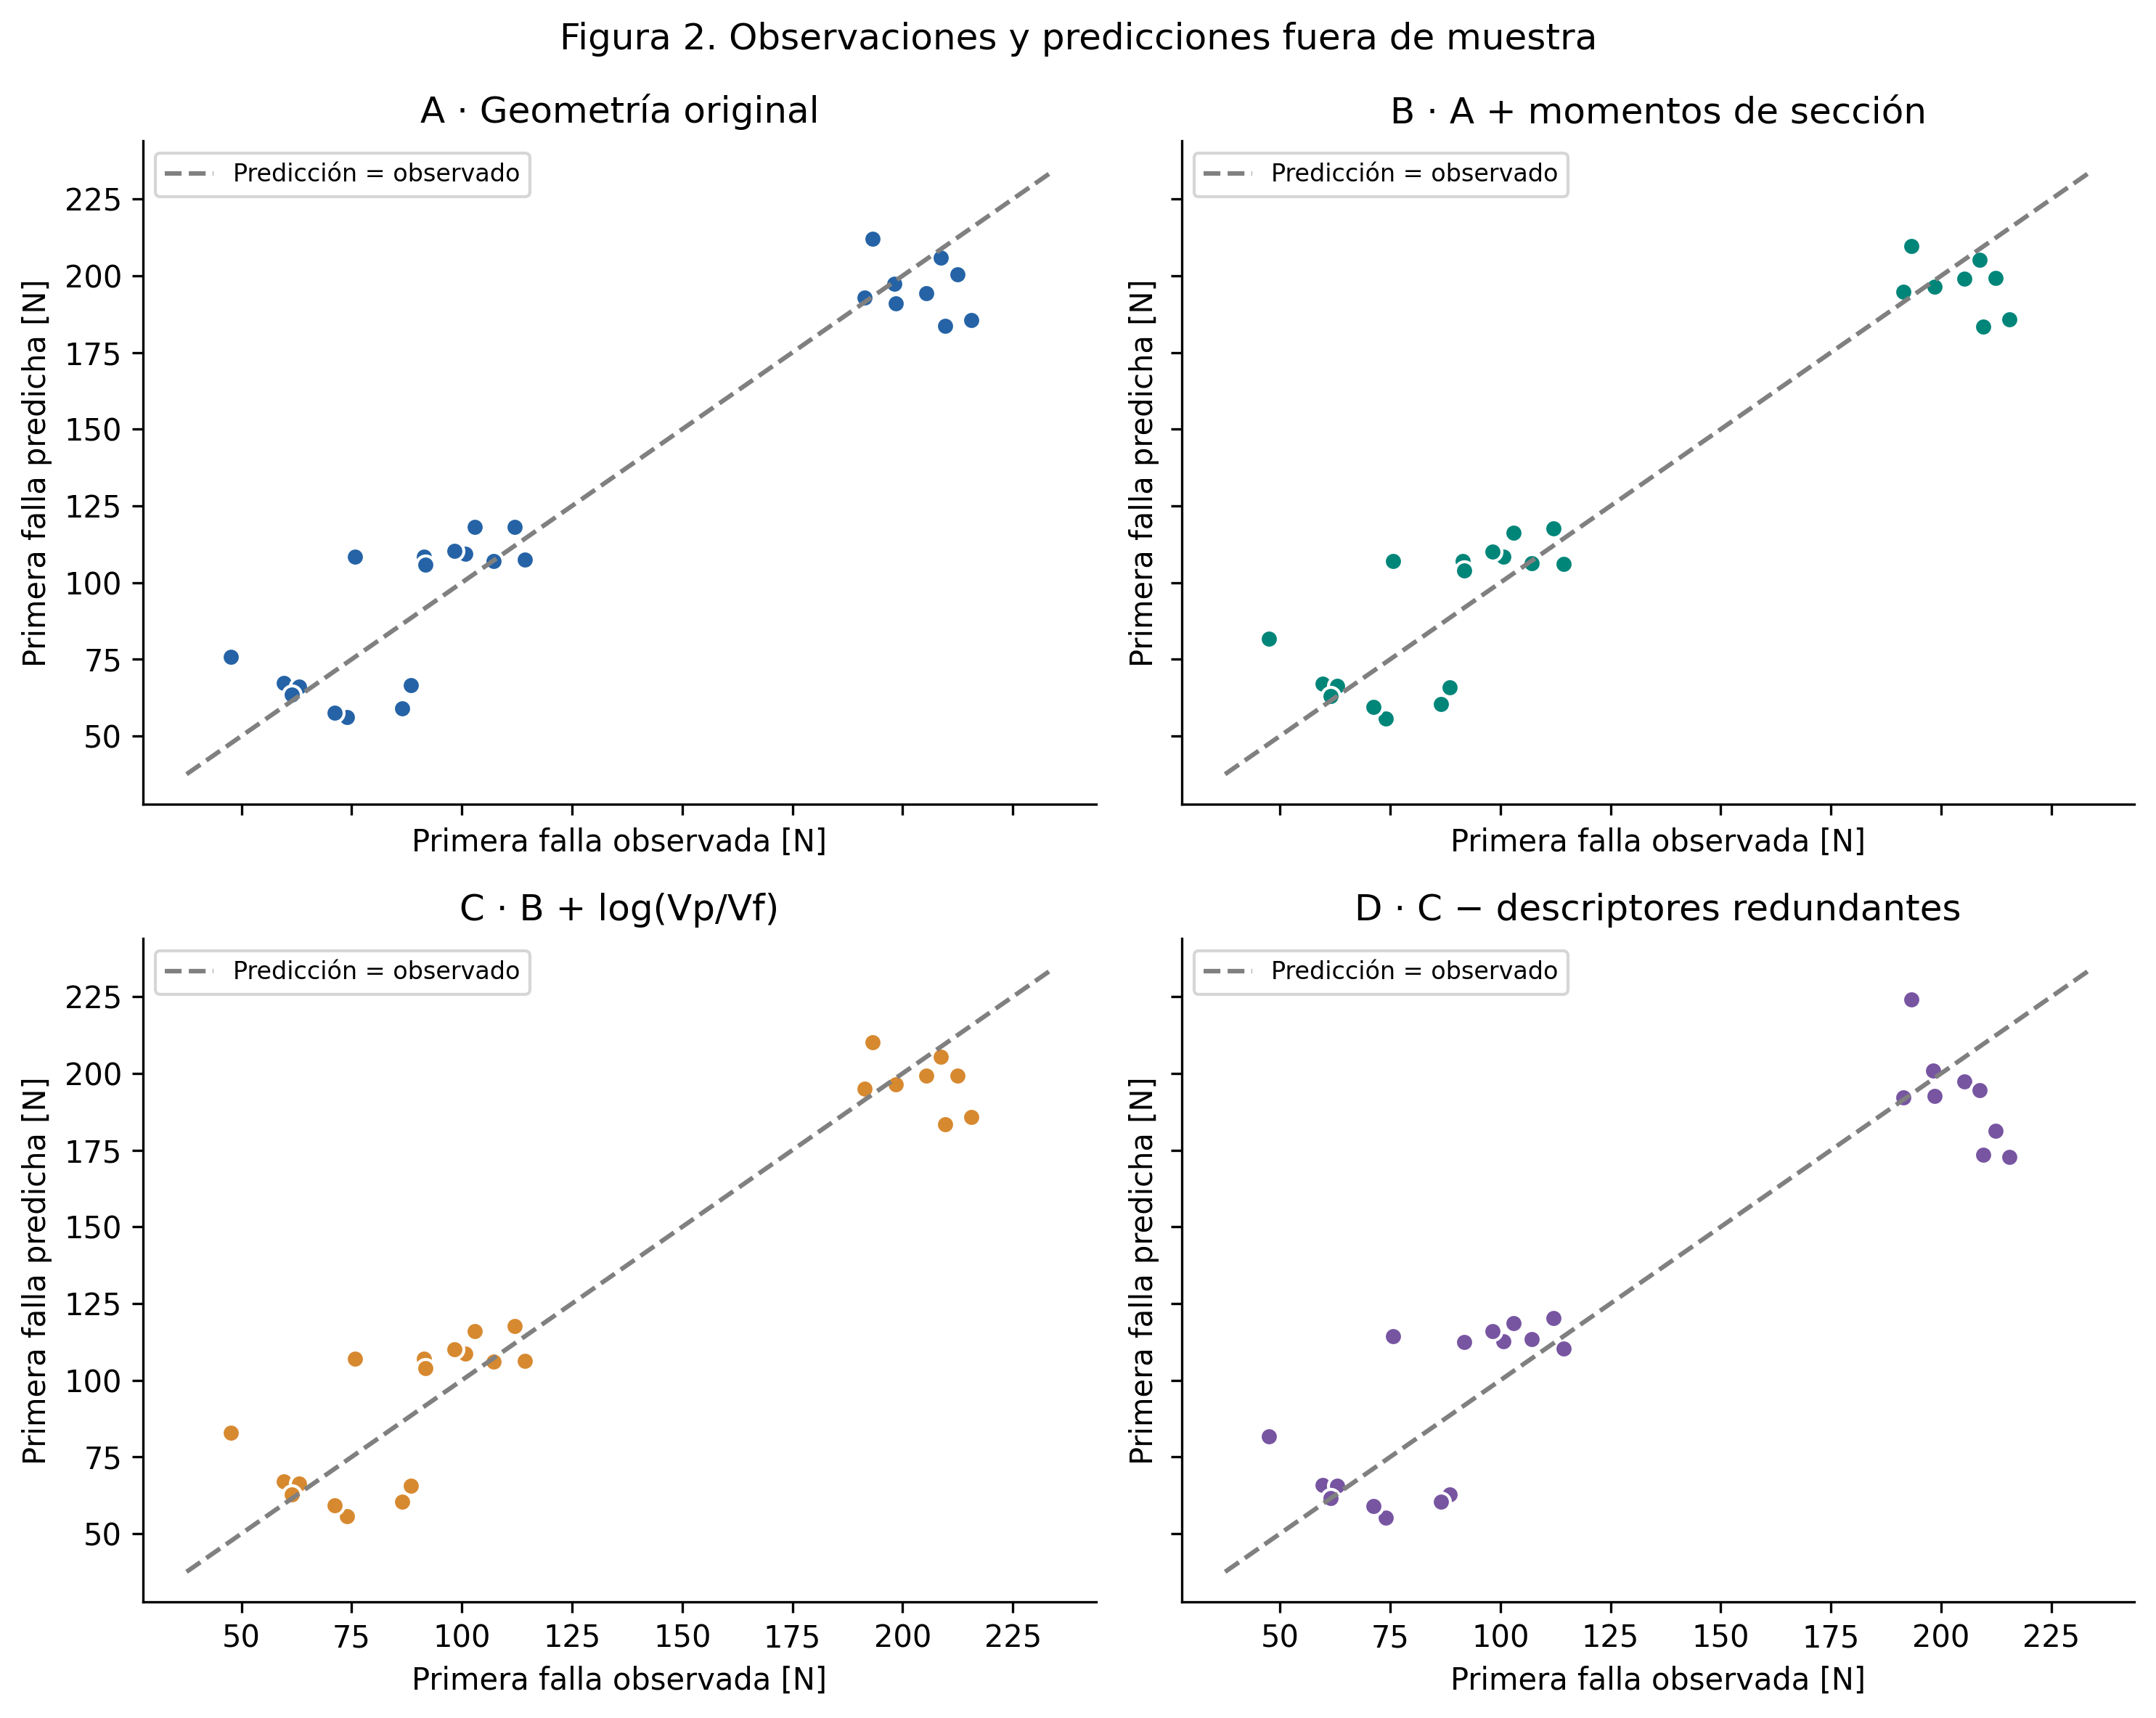

Cada punto es un caso validado excluyendo su configuración nominal. La línea de identidad indica coincidencia perfecta; distancias verticales representan errores. La agrupación por fuerzas puede reflejar familias; no demuestra precisión en arquitecturas nuevas.

**Fuente y unidades:** Tabla curada publicada; predicciones fuera de muestra bajo los protocolos indicados. Fuerzas y errores en N.

In [6]:
captions = json.loads((OUT/'leyendas.json').read_text(encoding='utf-8'))
c = captions[1]
display(Markdown('### '+c['title']))
display(Image(filename=str(OUT/'figures'/(c['file']+'.png')), width=1000))
display(Markdown(c['interpretation']+'\n\n**Fuente y unidades:** '+c['source']))

### Figura 3. Diagnóstico de residuales

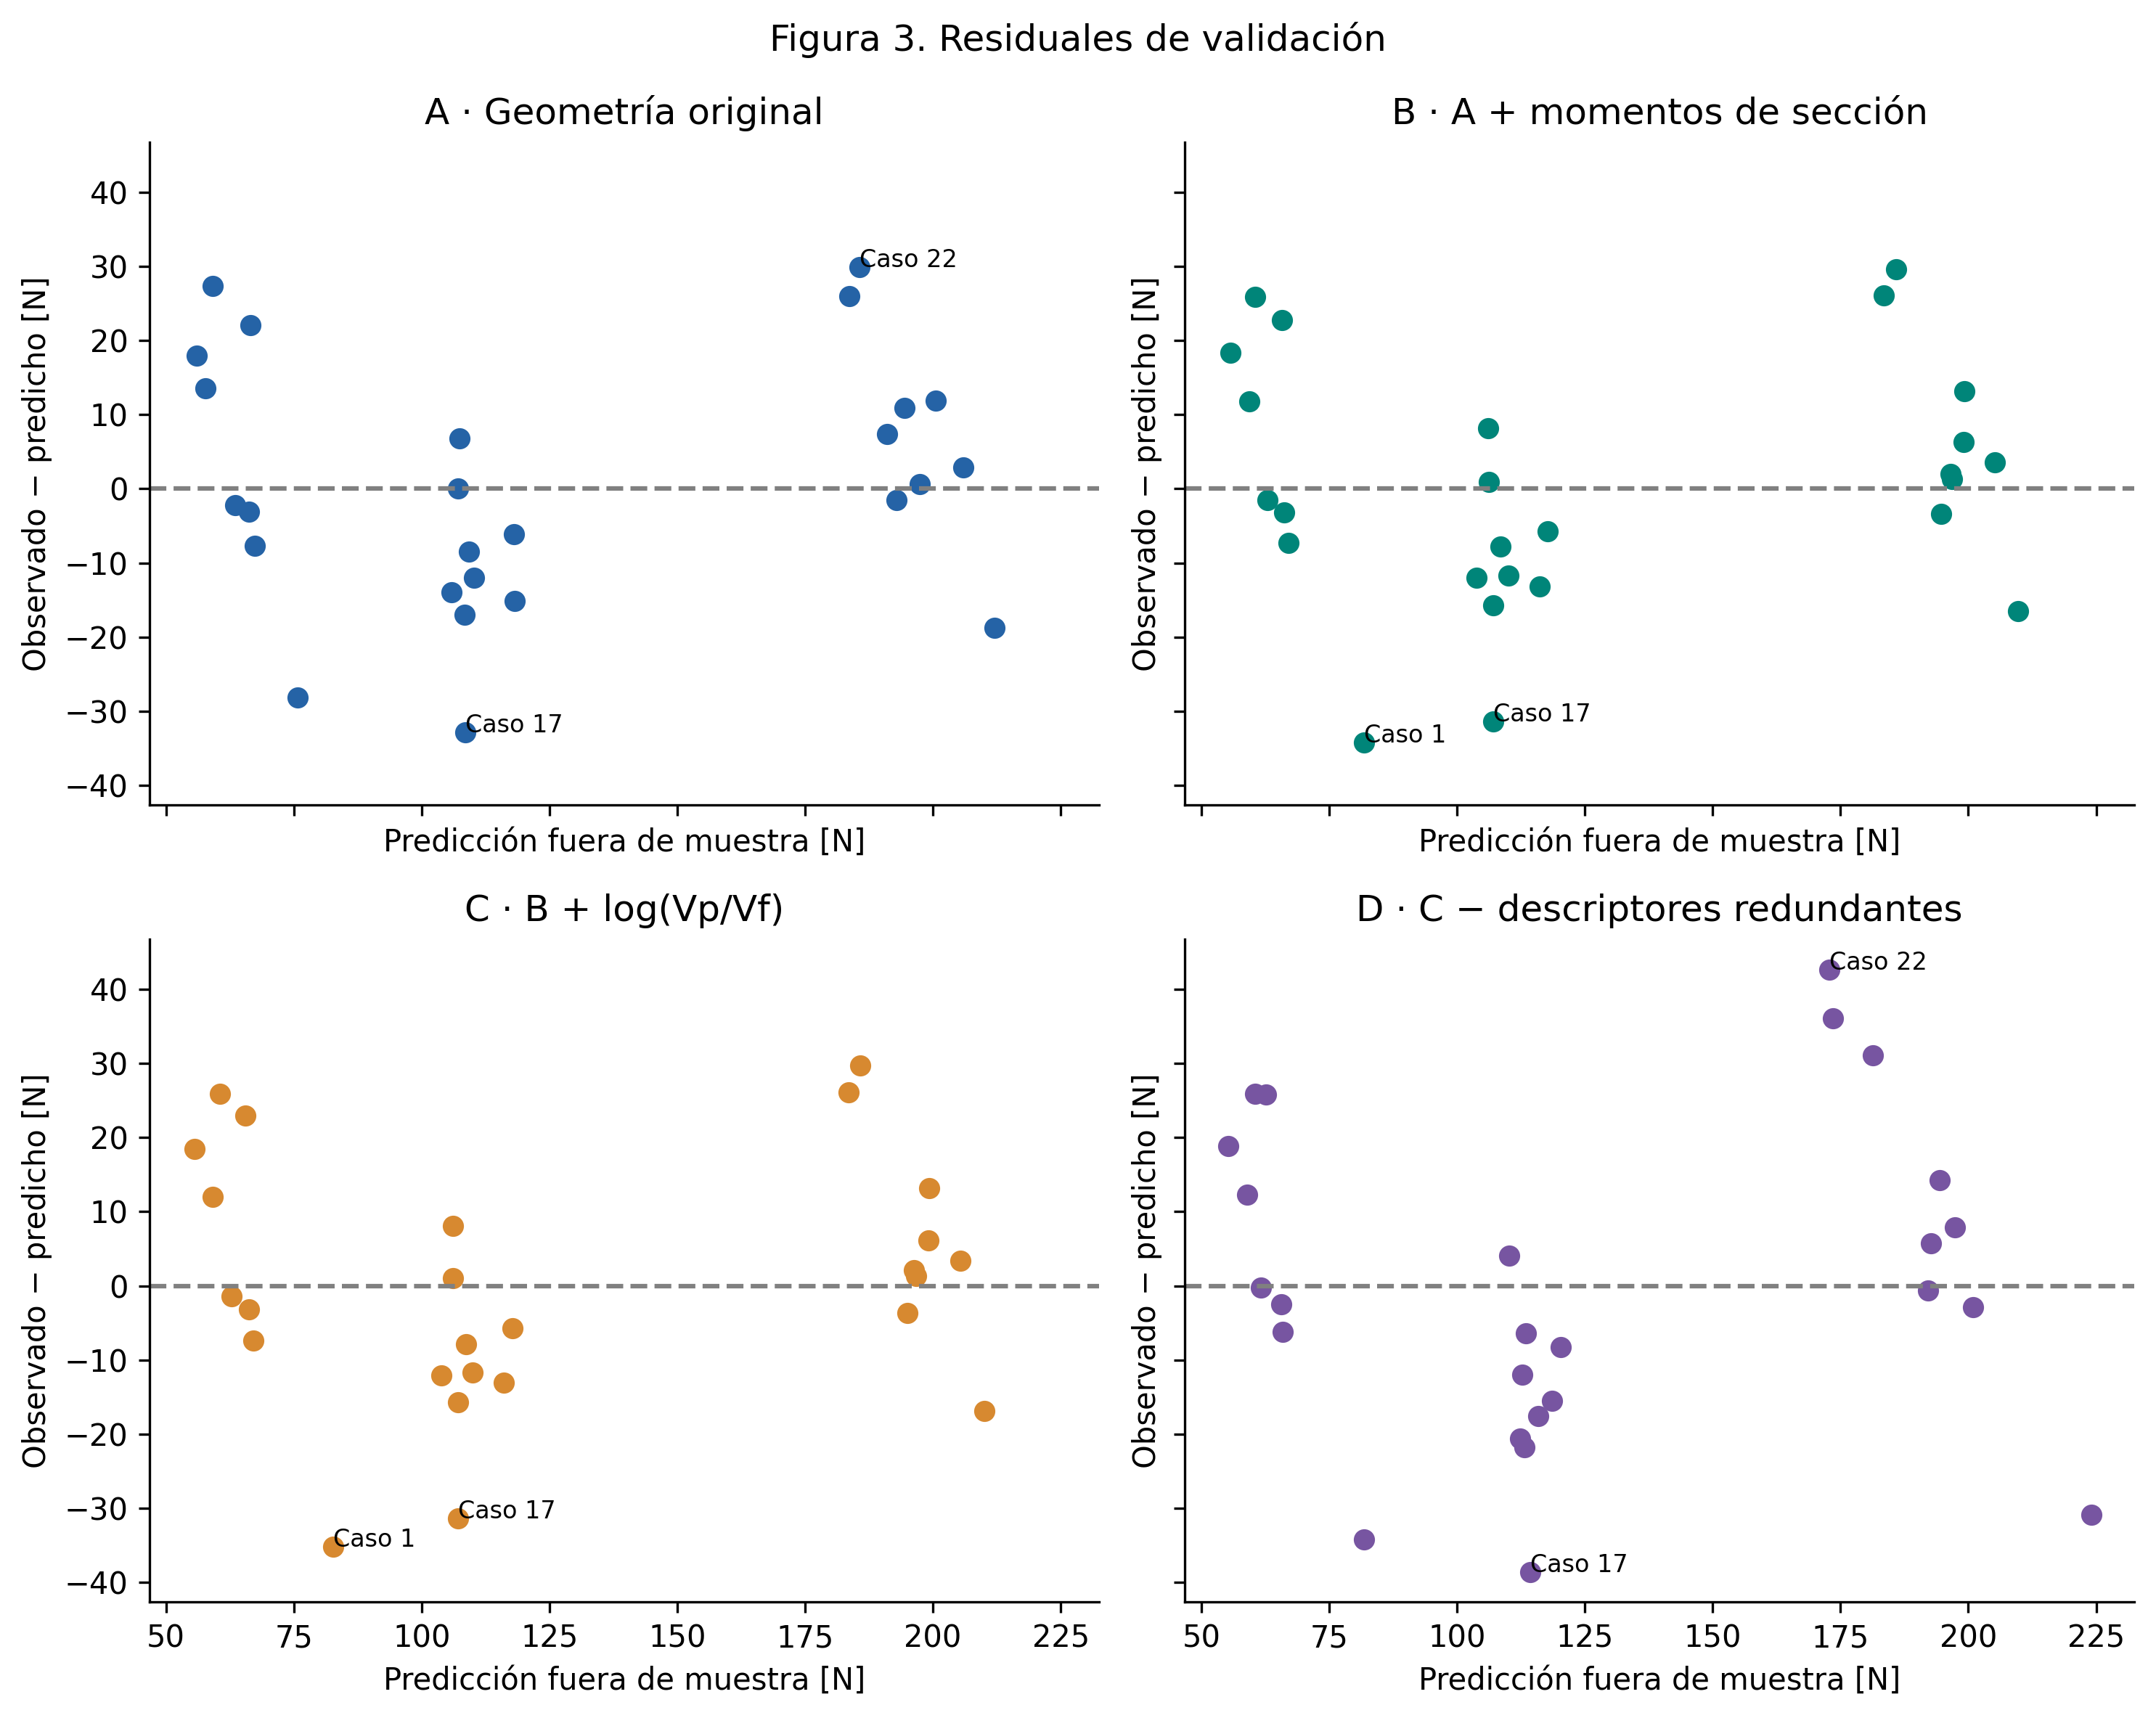

Residual = observado − predicho: positivo indica subestimación y negativo sobreestimación. Se identifican los dos errores absolutos mayores por variante para revisión, sin eliminarlos. La figura permite buscar sesgo y errores concentrados; no certifica normalidad ni independencia.

**Fuente y unidades:** Tabla curada publicada; predicciones fuera de muestra bajo los protocolos indicados. Fuerzas y errores en N.

In [7]:
captions = json.loads((OUT/'leyendas.json').read_text(encoding='utf-8'))
c = captions[2]
display(Markdown('### '+c['title']))
display(Image(filename=str(OUT/'figures'/(c['file']+'.png')), width=1000))
display(Markdown(c['interpretation']+'\n\n**Fuente y unidades:** '+c['source']))

### Figura 4. Error por familia y protocolo

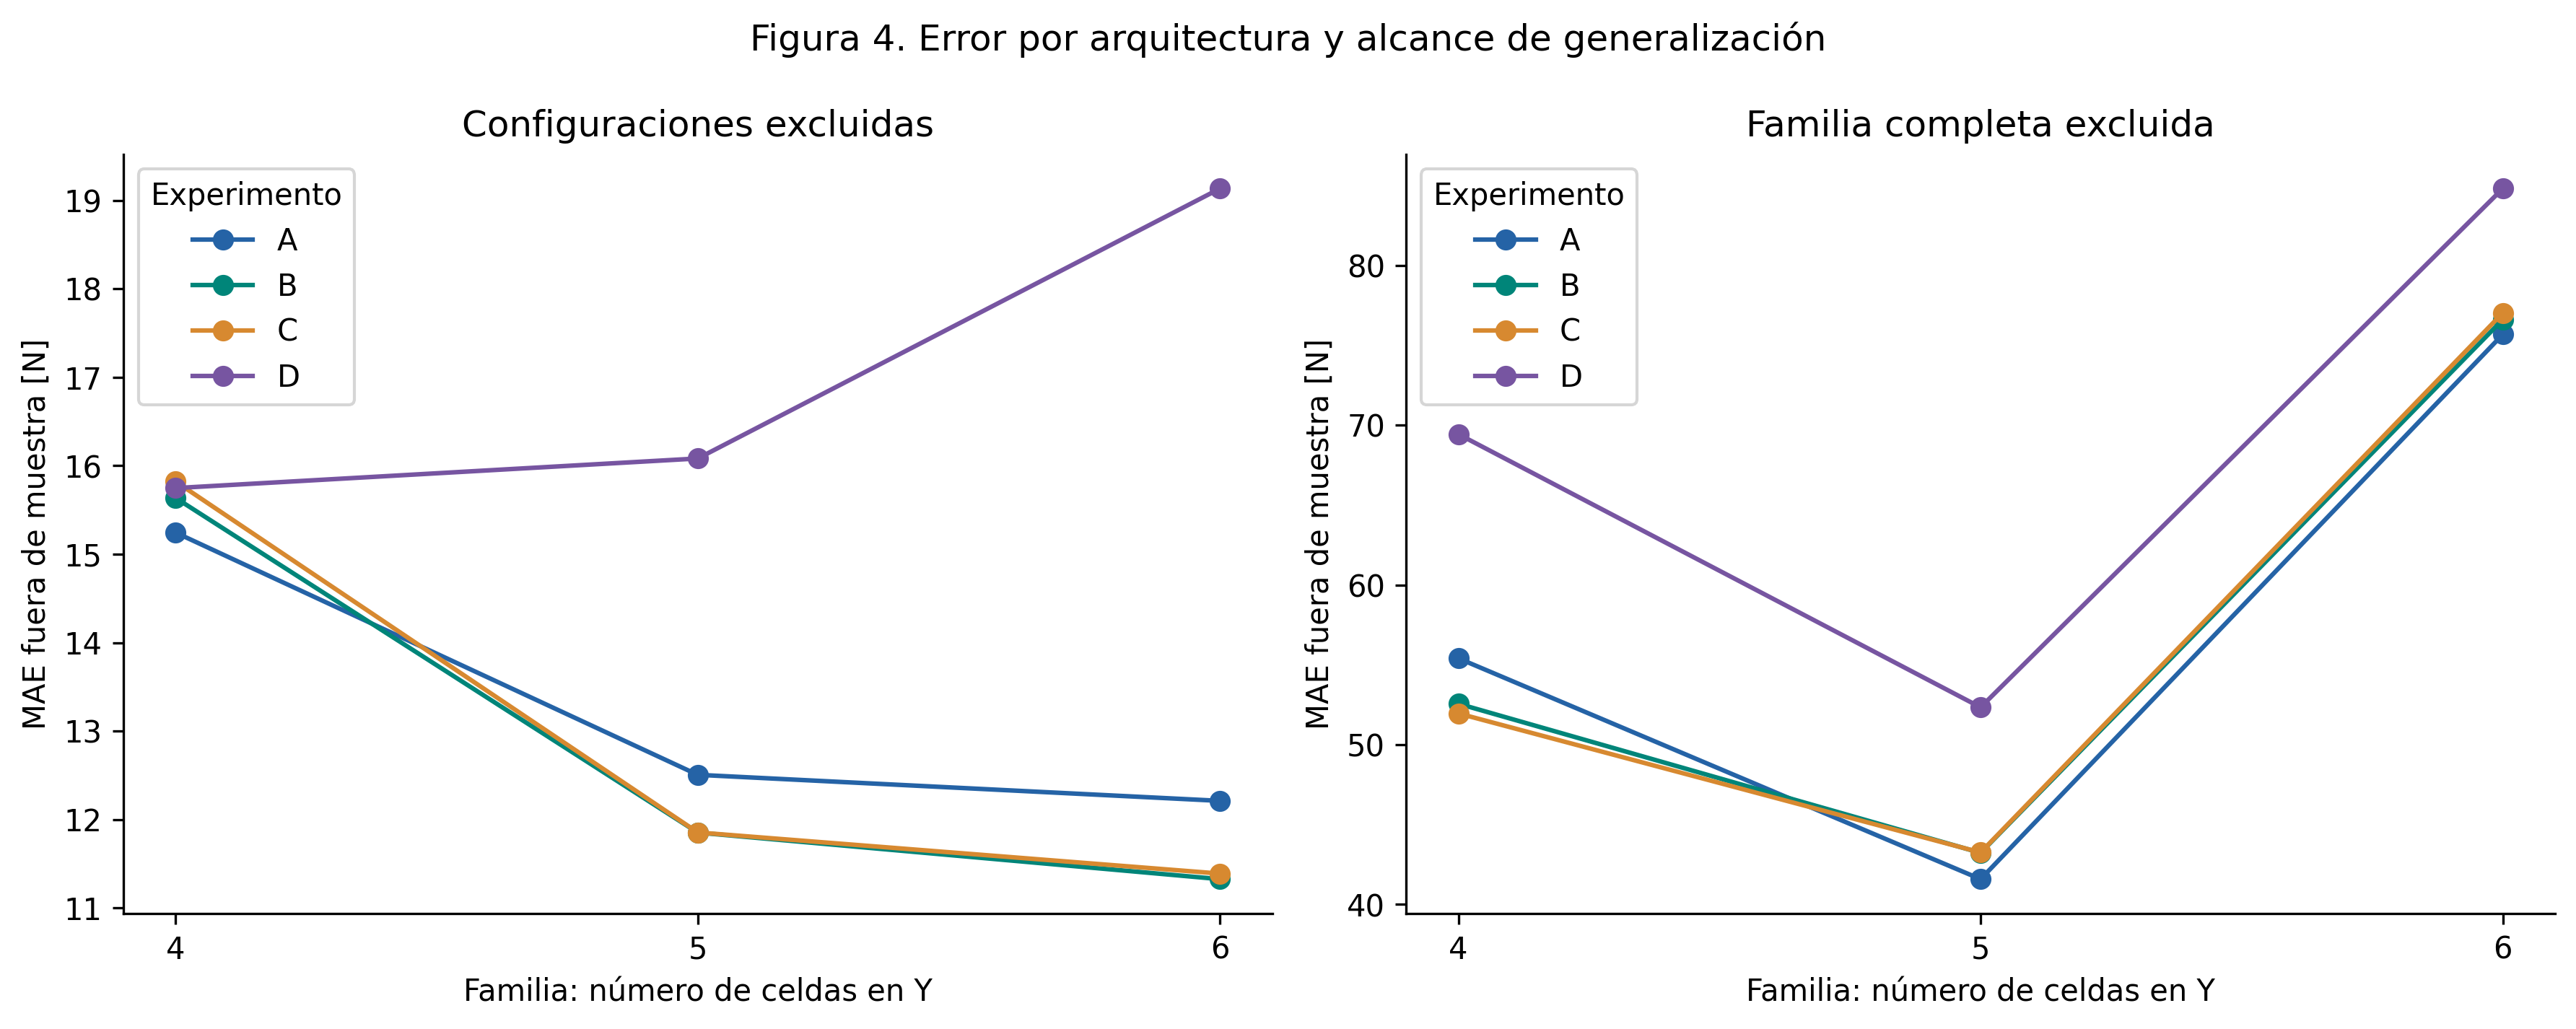

La comparación distingue configuraciones ausentes y familias completas ausentes. Para B, MAE pasa de 12.8346 N en el protocolo principal a 57.6538 N en el secundario. Son objetivos de generalización diferentes; la dispersión entre familias no es un intervalo de confianza.

**Fuente y unidades:** Tabla curada publicada; predicciones fuera de muestra bajo los protocolos indicados. Fuerzas y errores en N.

In [8]:
captions = json.loads((OUT/'leyendas.json').read_text(encoding='utf-8'))
c = captions[3]
display(Markdown('### '+c['title']))
display(Image(filename=str(OUT/'figures'/(c['file']+'.png')), width=1000))
display(Markdown(c['interpretation']+'\n\n**Fuente y unidades:** '+c['source']))

### Figura 5. Contribución incremental de las intervenciones

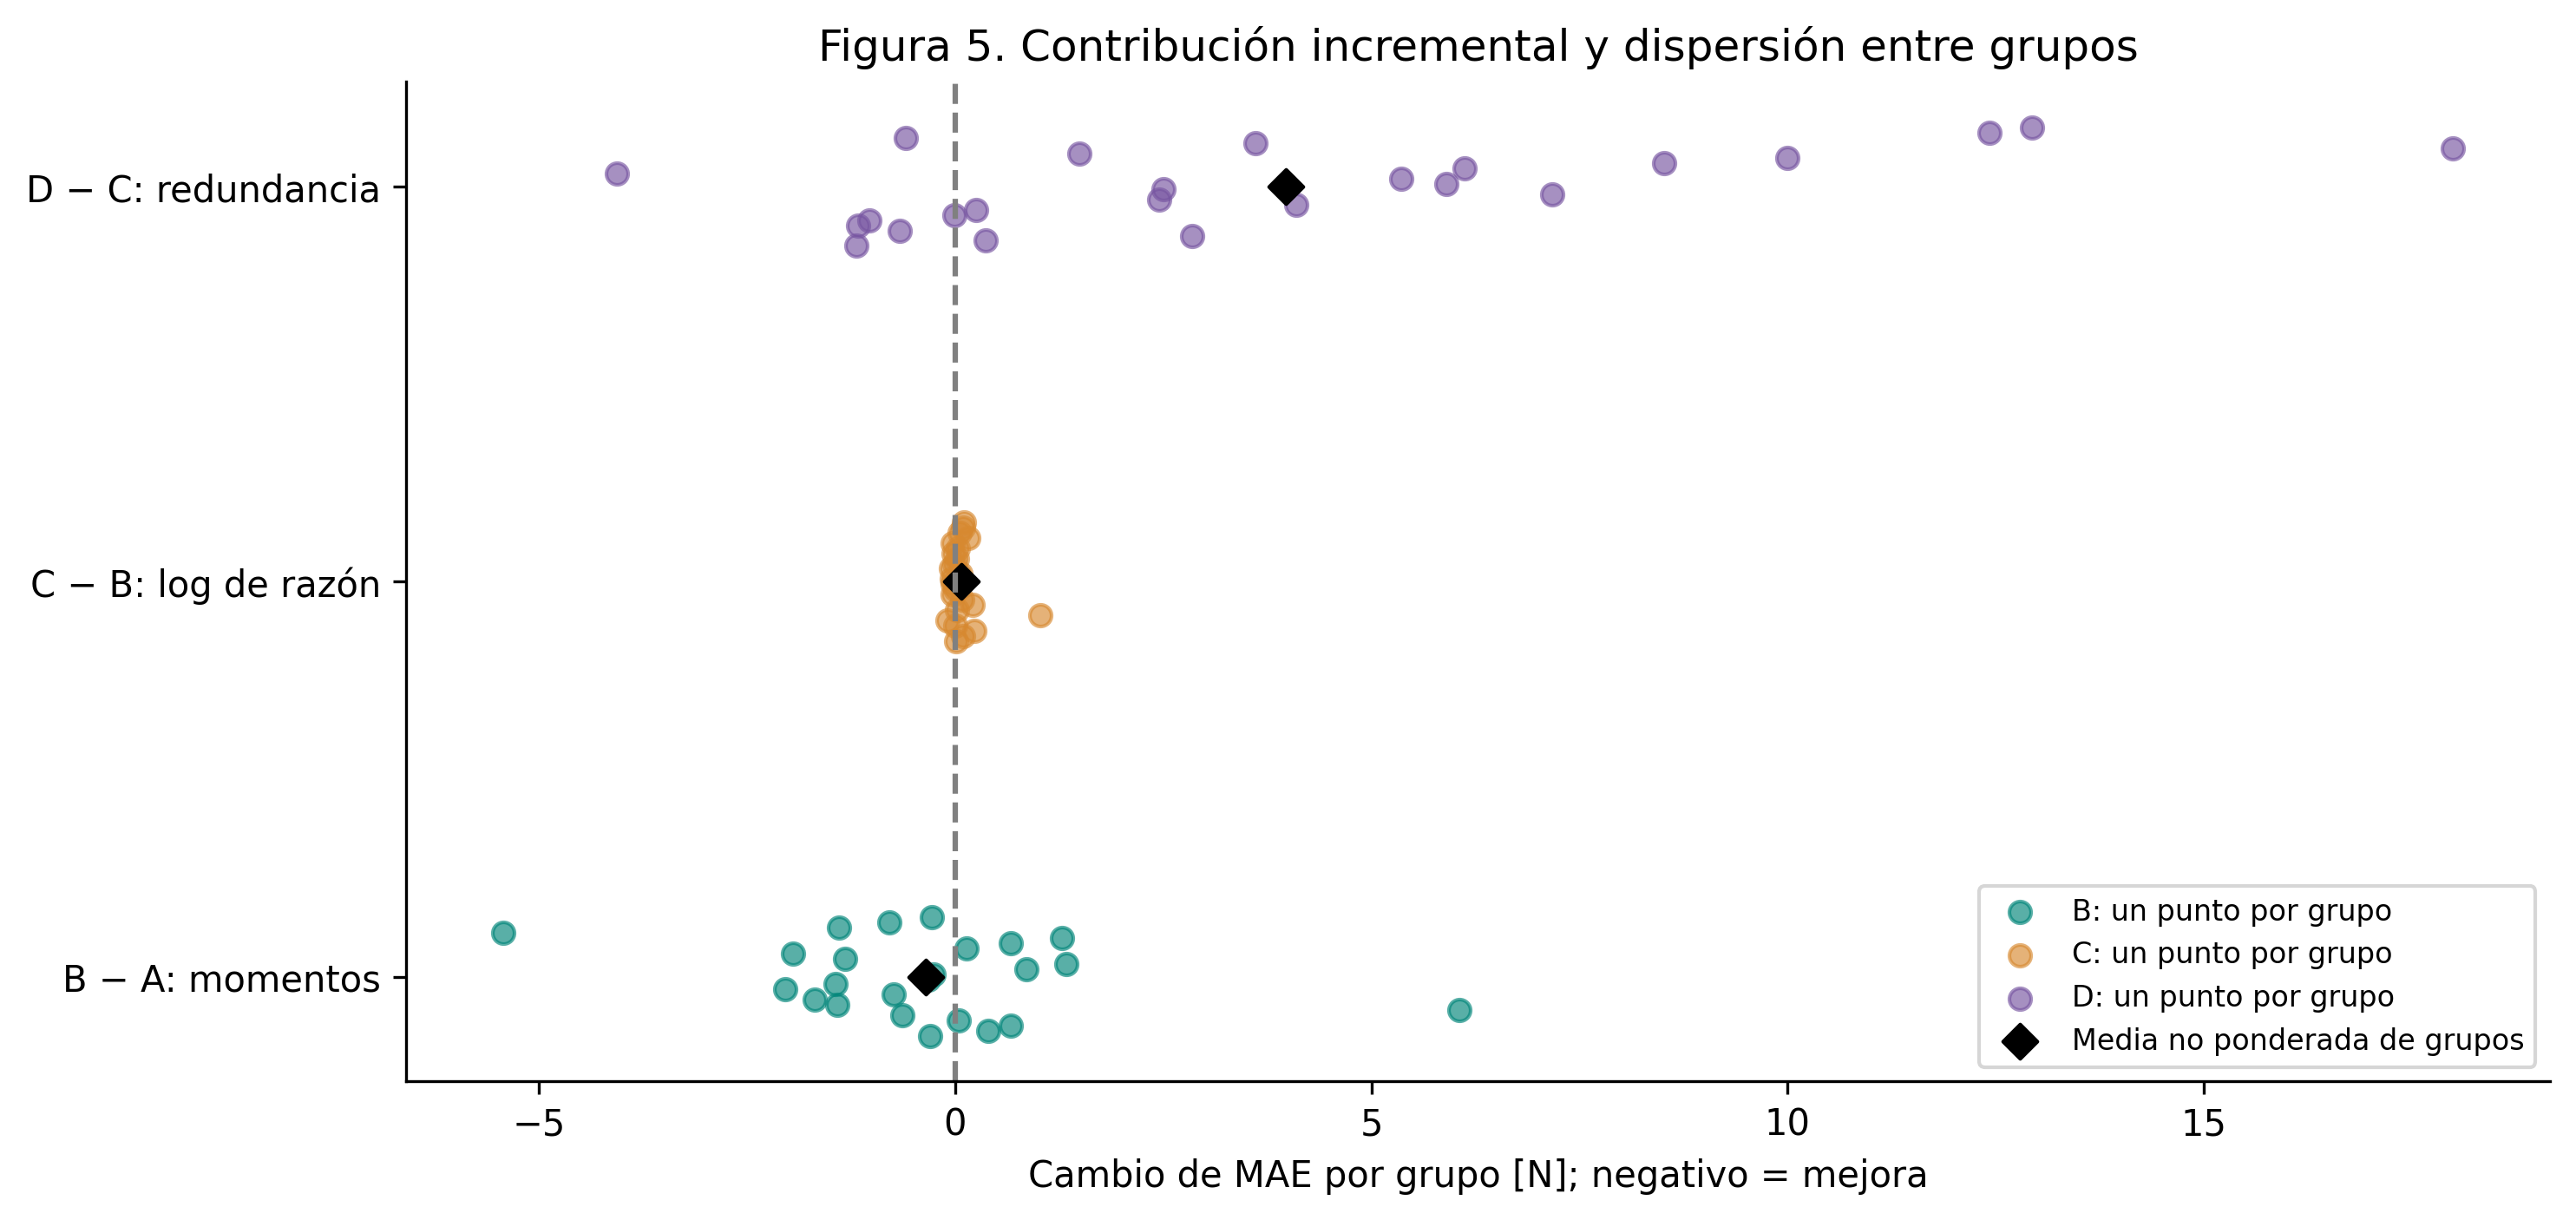

Cada punto es ΔMAE de un grupo bajo la misma partición; negativo favorece la intervención. El rombo muestra la media no ponderada de grupos, que puede diferir del ΔMAE ponderado por casos. La dispersión revela consistencia o heterogeneidad del aporte; no es importancia individual ni evidencia de información física nueva.

**Fuente y unidades:** Tabla curada publicada; predicciones fuera de muestra bajo los protocolos indicados. Fuerzas y errores en N.

In [9]:
captions = json.loads((OUT/'leyendas.json').read_text(encoding='utf-8'))
c = captions[4]
display(Markdown('### '+c['title']))
display(Image(filename=str(OUT/'figures'/(c['file']+'.png')), width=1000))
display(Markdown(c['interpretation']+'\n\n**Fuente y unidades:** '+c['source']))

## 4.6 Ablaciones y sensibilidad de los errores

In [10]:
display(table('decisiones'))
sensitivity=table('sensibilidad_scores')
display(sensitivity.loc[~sensitivity.escenario.str.startswith('omitir_score_grupo_')])
display(Markdown('La sensibilidad excluye scores del agregado OOF, no observaciones del entrenamiento. Su finalidad es detectar si pocos casos concentran la diferencia entre variantes.'))

,experimento,referencia,intervencion,delta_MAE_N,reduccion_MAE_pct,delta_RMSE_N,fraccion_grupos_mejora,delta_MAE_familia_N,decision
0,B,A,Añadir dos segundos momentos de área de la sec...,-0.411929,3.109705,-0.142860,0.625000,0.016371,Mantener en evaluación
1,C,B,Añadir ln(volumen_pivotes / volumen_fibras),0.079242,-0.617409,0.124249,0.375000,-0.034765,Descartar
2,D,C,"Retirar longitud total de fibras, número de pi...",4.121097,-31.912185,4.808964,0.291667,11.215063,Descartar


,experimento,referencia,escenario,n_scores,delta_MAE_N,alcance
0,B,A,todos,26,-0.411929,Solo cambia el agregado de errores OOF; modelo...
1,B,A,sin_scores_Cook_1_3,24,-0.726674,Solo cambia el agregado de errores OOF; modelo...
2,B,A,sin_scores_revision_pivote,23,-0.452410,Solo cambia el agregado de errores OOF; modelo...
27,C,B,todos,26,0.079242,Solo cambia el agregado de errores OOF; modelo...
28,C,B,sin_scores_Cook_1_3,24,0.033793,Solo cambia el agregado de errores OOF; modelo...
29,C,B,sin_scores_revision_pivote,23,0.075484,Solo cambia el agregado de errores OOF; modelo...
54,D,C,todos,26,4.121097,Solo cambia el agregado de errores OOF; modelo...
55,D,C,sin_scores_Cook_1_3,24,4.388899,Solo cambia el agregado de errores OOF; modelo...
56,D,C,sin_scores_revision_pivote,23,3.203284,Solo cambia el agregado de errores OOF; modelo...


La sensibilidad excluye scores del agregado OOF, no observaciones del entrenamiento. Su finalidad es detectar si pocos casos concentran la diferencia entre variantes.

## 4.7 Interpretación de resultados

In [11]:
report=(ROOT/'docs/experimentos_fe.md').read_text(encoding='utf-8')
for exp in 'BCD':
    part=report.split('## '+exp+' frente a ')[1]
    section='## '+exp+' frente a '+part.split('\n## ',1)[0]
    display(Markdown(section))
display(Markdown('## Conclusión y siguiente experimento\n'+report.split('## Conclusión y siguiente experimento')[1]))

## B frente a A

**Intervención:** Añadir dos segundos momentos de área de la sección de fibra. Su evidencia y justificación se detallan en la matriz EDA → FE y en el diccionario.

El cuaderno 03 evaluó b·h³/12 y h·b³/12, con asociaciones condicionadas próximas a cero. Se prueban porque la forma de la sección puede representar mecanismos de flexión, no porque su correlación prometa mejora. No se conoce aquí el módulo elástico ni se identifica el eje dominante. Añade dos columnas y hereda las discrepancias de Fiber_base.

El cambio de MAE es **-0.4119 N** (3.11 % de reducción) y el de RMSE **-0.1429 N**. Un RMSE menor indica menor penalización agregada de errores grandes, no que todos disminuyan. Mejora el MAE en **62.5 %** de grupos. Al excluir familias completas, el MAE cambia **+0.0164 N** frente a su referencia.

Dentro del protocolo principal, el cambio de MAE por familia es Y=4: +0.3916 N; Y=5: -0.6531 N; Y=6: -0.8850 N. Esto separa la mejora agregada de su distribución entre arquitecturas.

La mejora agrega o elimina funciones de las mismas mediciones: no aporta observaciones independientes. Los momentos y la razón heredan discrepancias de la fuente; D además cambia la distribución de la penalización Ridge. Se evalúa el bloque declarado, sin atribución individual a variables colineales.

Al omitir del agregado OOF un grupo cada vez, ΔMAE queda entre **-0.6708 y -0.2115 N**; su signo no cambia. Este diagnóstico cambia el score, no los modelos: los casos omitidos pudieron participar en otros entrenamientos. No reemplaza un estudio con nuevas mediciones.

| escenario | delta_MAE_N |
| --- | --- |
| sin_scores_Cook_1_3 | -0.7267 |
| sin_scores_revision_pivote | -0.4524 |

**Decisión: Mantener en evaluación.** Se aplica la regla declarada antes del experimento; el alcance es esta intervención con Ridge y estos protocolos, no una conclusión universal sobre la geometría.

## C frente a B

**Intervención:** Añadir ln(volumen_pivotes / volumen_fibras). Su evidencia y justificación se detallan en la matriz EDA → FE y en el diccionario.

El EDA encontró una asociación global positiva y condicionada negativa para ln(Vp/Vf). La hipótesis es representar de otra manera el reparto de volumen entre componentes. Añade una columna, pero Vf y Vp son complementarios en el diseño: la razón es una función no lineal de información ya disponible. La decisión depende de su diferencia de error frente a B.

El cambio de MAE es **+0.0792 N** (-0.62 % de reducción) y el de RMSE **+0.1242 N**. Un RMSE menor indica menor penalización agregada de errores grandes, no que todos disminuyan. Mejora el MAE en **37.5 %** de grupos. Al excluir familias completas, el MAE cambia **-0.0348 N** frente a su referencia.

Dentro del protocolo principal, el cambio de MAE por familia es Y=4: +0.1854 N; Y=5: +0.0015 N; Y=6: +0.0626 N. Esto separa la mejora agregada de su distribución entre arquitecturas.

La mejora agrega o elimina funciones de las mismas mediciones: no aporta observaciones independientes. Los momentos y la razón heredan discrepancias de la fuente; D además cambia la distribución de la penalización Ridge. Se evalúa el bloque declarado, sin atribución individual a variables colineales.

Al omitir del agregado OOF un grupo cada vez, ΔMAE queda entre **+0.0417 y +0.0862 N**; su signo no cambia. Este diagnóstico cambia el score, no los modelos: los casos omitidos pudieron participar en otros entrenamientos. No reemplaza un estudio con nuevas mediciones.

| escenario | delta_MAE_N |
| --- | --- |
| sin_scores_Cook_1_3 | 0.0338 |
| sin_scores_revision_pivote | 0.0755 |

**Decisión: Descartar.** Se aplica la regla declarada antes del experimento; el alcance es esta intervención con Ridge y estos protocolos, no una conclusión universal sobre la geometría.

## D frente a C

**Intervención:** Retirar longitud total de fibras, número de pivotes y volumen de fibras del bloque original. Su evidencia y justificación se detallan en la matriz EDA → FE y en el diccionario.

El EDA mostró una suma constante de volúmenes y un valor de longitud y de número de pivotes por familia. Se retiran tres columnas para probar simplificación. Aunque estén determinadas por la arquitectura observada, longitud y cantidad de pivotes pueden proporcionar funciones no lineales útiles a una regresión lineal; retirarlas y redistribuir la penalización puede empeorar la aproximación. El resultado no demuestra que los descriptores sean física o estadísticamente inútiles.

El cambio de MAE es **+4.1211 N** (-31.91 % de reducción) y el de RMSE **+4.8090 N**. Un RMSE menor indica menor penalización agregada de errores grandes, no que todos disminuyan. Mejora el MAE en **29.2 %** de grupos. Al excluir familias completas, el MAE cambia **+11.2151 N** frente a su referencia.

Dentro del protocolo principal, el cambio de MAE por familia es Y=4: -0.0741 N; Y=5: +4.2276 N; Y=6: +7.7437 N. Esto separa la mejora agregada de su distribución entre arquitecturas.

La mejora agrega o elimina funciones de las mismas mediciones: no aporta observaciones independientes. Los momentos y la razón heredan discrepancias de la fuente; D además cambia la distribución de la penalización Ridge. Se evalúa el bloque declarado, sin atribución individual a variables colineales.

Al omitir del agregado OOF un grupo cada vez, ΔMAE queda entre **+3.4288 y +4.5140 N**; su signo no cambia. Este diagnóstico cambia el score, no los modelos: los casos omitidos pudieron participar en otros entrenamientos. No reemplaza un estudio con nuevas mediciones.

| escenario | delta_MAE_N |
| --- | --- |
| sin_scores_Cook_1_3 | 4.3889 |
| sin_scores_revision_pivote | 3.2033 |

**Decisión: Descartar.** Se aplica la regla declarada antes del experimento; el alcance es esta intervención con Ridge y estos protocolos, no una conclusión universal sobre la geometría.



## Conclusión y siguiente experimento


El menor MAE del protocolo principal corresponde a **B**, con **12.8346 N**, frente a **13.2466 N** de A; reducción descriptiva de **3.11 %**. Al excluir familias completas, el MAE de B es **57.6538 N**. El ganador entre variantes examinadas no constituye una estimación independiente del rendimiento de un modelo seleccionado.

Se construyeron dos momentos de sección y una razón logarítmica; se probó también retirar un bloque redundante. Las decisiones por intervención son: B: Mantener en evaluación; C: Descartar; D: Descartar. **B es candidato para confirmación**, no un modelo validado para despliegue. Un resultado favorable solo en el dominio conocido no prueba transferencia a otra familia, material o campaña. Si la reducción falla, el resultado negativo delimita la utilidad de esta representación y regularización.

El EDA previo usó todas las observaciones y el target para formular hipótesis. Aunque las transformaciones se ajustan dentro de cada entrenamiento, existe posible sesgo de selección de hipótesis. Los resultados son exploratorios: se necesita una campaña independiente o una evaluación externa con el protocolo congelado. No se afirma causalidad, significación estadística ni seguridad estructural a partir de estas métricas.

Siguiente experimento propuesto, no ejecutado: congelar A y el candidato B, conciliar las geometrías señaladas con el proveedor y evaluar una campaña independiente con réplicas identificadas, manteniendo separados espécimen y lote. Registrar previamente MAE, límites de uso y regla de comparación. No generar datos sintéticos como sustituto de ensayos.


## 4.8 Artefactos y control de integridad

In [12]:
from src.ingesta import sha256_file
manifest=json.loads((OUT/'manifest.json').read_text(encoding='utf-8'))
assert all(sha256_file(ROOT/p)==v for p,v in manifest['inputs_sha256'].items())
assert all(sha256_file(OUT/p)==v for p,v in manifest['artifacts_sha256'].items())
display(Markdown('Resultados guardados en `reports/feature_engineering/`: predicciones OOF, métricas, particiones, estadísticas de entrenamiento, figuras y manifiesto. Integridad comprobada.'))

Resultados guardados en `reports/feature_engineering/`: predicciones OOF, métricas, particiones, estadísticas de entrenamiento, figuras y manifiesto. Integridad comprobada.